In [38]:
import pandas as pd
import numpy as np
import seaborn as sns

df = pd.read_parquet("../data/processed/dvf_77_2025_propre.parquet")
print(df.shape)

(13722, 14)


In [39]:
df["prix_m2"].describe()

count     13722.000000
mean       3146.983883
std        2797.664085
min           0.012500
25%        2380.952381
50%        3069.760770
75%        3767.248062
max      300000.000000
Name: prix_m2, dtype: float64

In [40]:
q1 = df["prix_m2"].quantile(0.25)

q3 = df["prix_m2"].quantile(0.75)

iqr = q3 - q1

borne_basse = q1 - 1.5*iqr

borne_haute = q3 + 1.5*iqr

print(f"Q1 (25%)        : {q1:.2f} €")
print(f"Q3 (75%)        : {q3:.2f} €")
print(f"IQR             : {iqr:.2f} €")
print(f"Borne basse     : {borne_basse:.2f} €")
print(f"Borne haute     : {borne_haute:.2f} €")

Q1 (25%)        : 2380.95 €
Q3 (75%)        : 3767.25 €
IQR             : 1386.30 €
Borne basse     : 301.51 €
Borne haute     : 5846.69 €


In [41]:
nb_inferieurs = (df['prix_m2'] < borne_basse).sum()
print(f"Nombre de valeurs inférieures à {borne_basse:.2f} € : {nb_inferieurs}")

nb_superieurs = (df['prix_m2'] > borne_haute).sum()
print(f"Nombre de valeurs supérieures à {borne_haute:.2f} : {nb_superieurs}")

Nombre de valeurs inférieures à 301.51 € : 33
Nombre de valeurs supérieures à 5846.69 : 208


In [42]:
colonnes_a_afficher = ['nb_dependances', 'type_local', 'prix_m2', 'valeur_fonciere', 'surface_reelle_bati']

condition_outliers_basse = (df['prix_m2'] < borne_basse) 

condition_outliers_haute = (df['prix_m2'] > borne_haute)


df_outliers_selection_basse = df.loc[condition_outliers_basse, colonnes_a_afficher].sort_values(by='prix_m2', ascending=True)

df_outliers_selection_haute = df.loc[condition_outliers_haute, colonnes_a_afficher].sort_values(by='prix_m2', ascending=False)

In [43]:
print(df_outliers_selection_basse.head(33))

       nb_dependances   type_local     prix_m2  valeur_fonciere  \
8579                0       Maison    0.012500              1.0   
5599                2  Appartement    0.020000              1.0   
13016               0       Maison    0.465909             41.0   
9769                0  Appartement    1.000000            100.0   
5716                0  Appartement   26.666667            800.0   
4145                0       Maison   29.333333            440.0   
8227                4       Maison   31.007752           4000.0   
6229                0       Maison   50.000000           1000.0   
5984                1  Appartement   60.493827           4900.0   
12285               0       Maison   67.114286           9396.0   
10886               0  Appartement   83.333333           5000.0   
12321               1       Maison   91.908000          11488.5   
1706                2       Maison  101.333333           7600.0   
7214                0       Maison  107.526882          20000.

In [44]:
print(df_outliers_selection_haute.to_string())

       nb_dependances   type_local        prix_m2  valeur_fonciere  surface_reelle_bati
9765                2  Appartement  300000.000000        300000.00                  1.0
8132                3       Maison   37973.888462       4936605.50                130.0
6301                0       Maison   15000.000000       1500000.00                100.0
4258                1       Maison   14783.333333        709600.00                 48.0
3604                1       Maison   14107.500000       1128600.00                 80.0
10109               1  Appartement   14050.000000        281000.00                 20.0
12911               1       Maison   13400.000000        134000.00                 10.0
4647                1       Maison   13333.333333       1200000.00                 90.0
1338                0       Maison   12666.666667        950000.00                 75.0
4932                1       Maison   11166.666667        335000.00                 30.0
5194                1  Apparteme

In [45]:
lignes_a_supprimer = (df['surface_reelle_bati'] < 9) | (df['prix_m2'] < 26)

df_nettoye = df[~lignes_a_supprimer].copy()

print(f"Nombre de lignes avant nettoyage : {len(df)}")
print(f"Nombre de lignes après nettoyage : {len(df_nettoye)}")
print(f"Nombre de lignes supprimées : {len(df) - len(df_nettoye)}")


Nombre de lignes avant nettoyage : 13722
Nombre de lignes après nettoyage : 13717
Nombre de lignes supprimées : 5


In [46]:
nb_inferieurs = (df_nettoye['prix_m2'] < borne_basse).sum()
print(f"Nombre de valeurs inférieures à {borne_basse:.2f} € : {nb_inferieurs}")

nb_superieurs = (df_nettoye['prix_m2'] > borne_haute).sum()
print(f"Nombre de valeurs supérieures à {borne_haute:.2f} : {nb_superieurs}")

Nombre de valeurs inférieures à 301.51 € : 29
Nombre de valeurs supérieures à 5846.69 : 207


In [47]:
df_outliers_selection_basse_nettoye = df_nettoye.loc[condition_outliers_basse, colonnes_a_afficher].sort_values(by='prix_m2', ascending=True)

df_outliers_selection_haute_nettoye = df_nettoye.loc[condition_outliers_haute, colonnes_a_afficher].sort_values(by='prix_m2', ascending=False)


In [48]:
print(df_outliers_selection_basse_nettoye.to_string())

       nb_dependances   type_local     prix_m2  valeur_fonciere  surface_reelle_bati
5716                0  Appartement   26.666667            800.0                 30.0
4145                0       Maison   29.333333            440.0                 15.0
8227                4       Maison   31.007752           4000.0                129.0
6229                0       Maison   50.000000           1000.0                 20.0
5984                1  Appartement   60.493827           4900.0                 81.0
12285               0       Maison   67.114286           9396.0                140.0
10886               0  Appartement   83.333333           5000.0                 60.0
12321               1       Maison   91.908000          11488.5                125.0
1706                2       Maison  101.333333           7600.0                 75.0
7214                0       Maison  107.526882          20000.0                186.0
8517                1  Appartement  111.764706           3800.0  

In [49]:
print(df_outliers_selection_haute_nettoye.to_string())

       nb_dependances   type_local       prix_m2  valeur_fonciere  surface_reelle_bati
8132                3       Maison  37973.888462       4936605.50                130.0
6301                0       Maison  15000.000000       1500000.00                100.0
4258                1       Maison  14783.333333        709600.00                 48.0
3604                1       Maison  14107.500000       1128600.00                 80.0
10109               1  Appartement  14050.000000        281000.00                 20.0
12911               1       Maison  13400.000000        134000.00                 10.0
4647                1       Maison  13333.333333       1200000.00                 90.0
1338                0       Maison  12666.666667        950000.00                 75.0
4932                1       Maison  11166.666667        335000.00                 30.0
5194                1  Appartement  10733.333333        161000.00                 15.0
13461               2       Maison  10555.5

In [50]:
df_nettoye["prix_m2"].describe()

count    13717.000000
mean      3126.260213
std       1183.943442
min         26.666667
25%       2381.578947
50%       3070.000000
75%       3767.441860
max      37973.888462
Name: prix_m2, dtype: float64

<Axes: xlabel='prix_m2', ylabel='Count'>

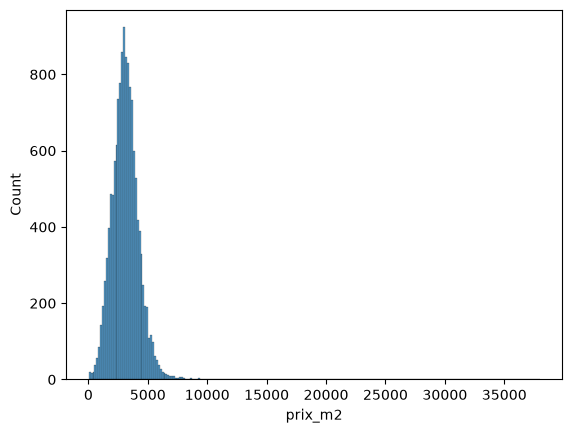

In [51]:
sns.histplot(data=df_nettoye, x="prix_m2")

<Axes: xlabel='prix_m2'>

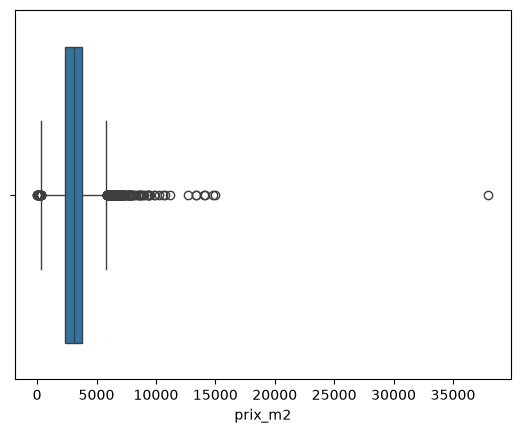

In [52]:
sns.boxplot(data=df_nettoye, x="prix_m2")

<Axes: xlabel='prix_m2_log', ylabel='Count'>

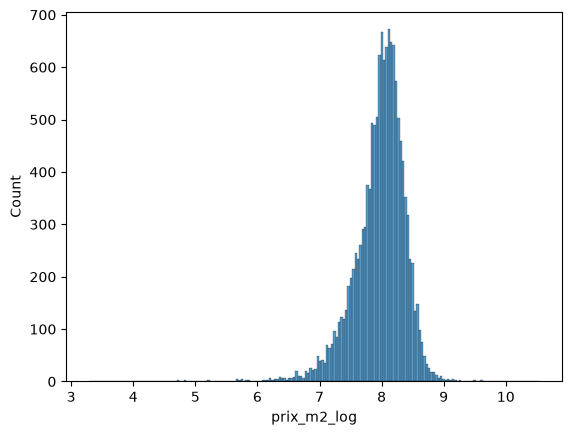

In [55]:
df_nettoye["prix_m2_log"] = np.log(df_nettoye["prix_m2"])
sns.histplot(data=df_nettoye, x="prix_m2_log")

In [56]:
df_nettoye.groupby("type_local")["prix_m2"].describe()

,count,mean,std,min,25%,50%,75%,max
type_local,,,,,,,,
Appartement,5988.0,3309.456363,1076.097131,26.666667,2580.483871,3284.044566,4000.000000,14050.000000
Maison,7729.0,2984.330010,1242.810949,29.333333,2241.353383,2926.829268,3574.712644,37973.888462


<Axes: xlabel='type_local', ylabel='prix_m2'>

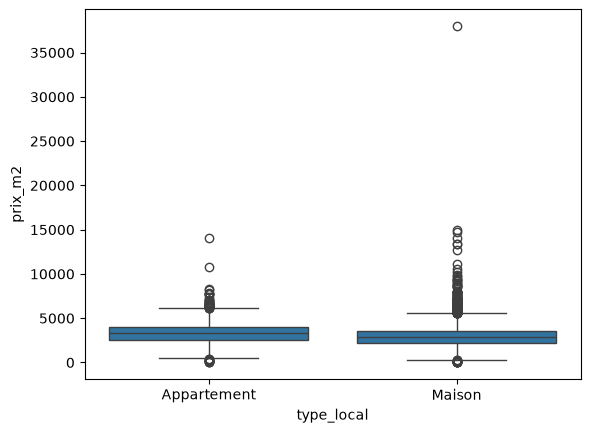

In [57]:
sns.boxplot(data=df_nettoye, x="type_local", y="prix_m2")

<Axes: xlabel='surface_reelle_bati', ylabel='prix_m2'>

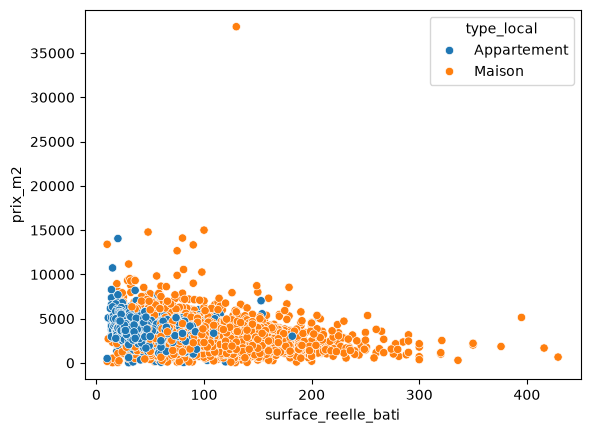

In [58]:
sns.scatterplot(data=df_nettoye, x="surface_reelle_bati", y="prix_m2", hue="type_local")

In [59]:
tranches = pd.cut(df_nettoye["surface_reelle_bati"], bins=[0, 50, 100, 150, 200, 300, 500])
df_nettoye.groupby(tranches)["prix_m2"].median()

surface_reelle_bati
(0, 50]       3689.635279
(50, 100]     3066.666667
(100, 150]    2685.185185
(150, 200]    2255.767742
(200, 300]    1936.463303
(300, 500]    1770.867430
Name: prix_m2, dtype: float64

## Conclusion

Ce notebook part du dataset nettoyé au notebook 03 (`dvf_77_2025_propre.parquet`, 13 722 ventes) et étudie la distribution de `prix_m2`, la cible de l'analyse.

**Détection des valeurs extrêmes avec la règle de Tukey (IQR) :**

Le `describe()` initial montrait un `min` de 0,01 €/m² et un `max` de 300 000 €/m², à comparer à une médiane de 3 070 €/m². La règle de Tukey (bornes à Q1 − 1,5×IQR et Q3 + 1,5×IQR) a identifié 241 ventes statistiquement atypiques (33 sous la borne basse de 301,51 €/m², 208 au-dessus de la borne haute de 5 846,69 €/m²), soit 1,8 % des ventes.

**Une règle statistique ne suffit pas à décider : il faut inspecter.**

Plutôt que de supprimer mécaniquement ces 241 ventes, chaque groupe a été inspecté pour distinguer les vraies anomalies des valeurs simplement rares mais plausibles :

- **Côté bas :** en triant les 33 ventes par `prix_m2` croissant, une rupture nette (facteur ×27) apparaît entre 1 €/m² et 26,67 €/m², suivie d'une progression fluide et réaliste. Les 4 ventes sous cette rupture (1 €, 1 €, 41 € et 100 €) ont un prix clairement symbolique, probablement des donations déguisées en vente plutôt que de vraies transactions de marché.
- **Côté haut :** une seule vraie anomalie, une vente à 300 000 €/m² portée par une surface de 1 m² — une surface manifestement erronée, pas un vrai prix. Les autres valeurs élevées (jusqu'à 37 974 €/m² pour une propriété à 4 936 605 €) ont été jugées plausibles : ce sont des biens de luxe, pas des erreurs.

**Règle de filtrage retenue, basée sur deux seuils justifiés plutôt que sur l'IQR :**

1. `surface_reelle_bati < 9` m² : seuil légal français de logement décent, qui élimine la vente à 1 m².
2. `prix_m2 < 26` €/m² : seuil basé sur la rupture observée, qui élimine les 4 prix symboliques.

Cette règle ne retire que **5 ventes sur 13 722**, contre 241 pour une application mécanique de l'IQR. Son efficacité est confirmée par la baisse de l'écart-type, divisé par plus de deux (de 2 797 à 1 184 €/m²), alors que la médiane reste quasiment inchangée (3 070 €/m²) : les 5 ventes retirées étaient bien les seules à perturber la distribution, sans qu'il ait fallu sacrifier des ventes légitimes.

**Visualisations et hypothèses confirmées :**

- L'histogramme de `prix_m2` montre une distribution asymétrique à droite (*right-skewed*), avec un pic autour de 2 500-3 500 €/m² et une longue traîne vers les valeurs élevées. Une transformation logarithmique (`np.log`) rend cette distribution beaucoup plus symétrique, confirmant que l'asymétrie vient bien de la traîne et non d'une structure à plusieurs groupes.
- La comparaison par `type_local` montre une médiane plus élevée pour les appartements (3 284 €/m²) que pour les maisons (2 927 €/m²), cohérent avec une concentration des appartements en zone plus urbaine/dense et des maisons en zone rurale/périurbaine, plus abordable.
- La relation entre surface et prix au m² (nuage de points, puis confirmation chiffrée par tranches de surface) montre un effet de taille classique en immobilier : la médiane de `prix_m2` passe de 3 690 €/m² (0-50 m²) à 1 771 €/m² (300-500 m²), soit plus du double d'écart entre petites et grandes surfaces.

**Bilan :** de 13 722 à **13 717 ventes**, dans `df_nettoye`, prêt pour les prochaines questions d'analyse (caractéristiques du bien, communes, distance à Paris, évolution mensuelle).